# NearMiss — Traffic Analysis and Prediction
CSE3141 · Manipal University Jaipur

Predict front-to-front time headway below 1.5 s at any observation in the next 2 s. This predicts close following, **not crashes**. Existing short headways can persist: this is event presence, not exclusively new onset. Compare Logistic Regression, LDA and QDA. No handout was attached; alignment follows the supplied syllabus list.

In [1]:
from pathlib import Path
import json, hashlib, io
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, RocCurveDisplay
ROOT = Path.cwd() if Path('backend').exists() else Path.cwd().parent
RAW=ROOT/'data/raw'; OUT=ROOT/'backend/artifacts'; PUBLIC=ROOT/'frontend/public/data'
for p in [RAW,OUT,PUBLIC]: p.mkdir(parents=True,exist_ok=True)
ORIGIN=1118846978900
SOURCE='https://data.transportation.gov/resource/8ect-6jqj'
sns.set_theme(style='whitegrid')

## 1. Genuine data and units
https://data.transportation.gov/d/8ect-6jqj . DOT defines spacing/length in feet, velocity in ft/s, acceleration in ft/s², timestamp in ms. Spacing is **front-to-front**, not bumper gap. Retain one complete recording origin (global_time − frame_id × 100), preserving all 10 Hz frames. Three US-101 origins exist; use one here. Download pages ordered by vehicle/frame; export SHA-256.

In [2]:
path=RAW/'us101_complete_recording.csv'
columns='vehicle_id,frame_id,global_time,local_x,local_y,v_length,v_width,v_vel,v_acc,lane_id,preceding,following,space_headway,location'
where=f"location='us-101' AND global_time-frame_id*100={ORIGIN}"
if not path.exists():
    pages=[]
    for offset in range(0,2000000,10000):
        r=requests.get(SOURCE+'.csv',params={'$select':columns,'$where':where,'$order':'vehicle_id,frame_id','$limit':10000,'$offset':offset},timeout=120)
        r.raise_for_status(); page=pd.read_csv(io.StringIO(r.text))
        if page.empty: break
        pages.append(page)
        if len(page)<10000: break
    pd.concat(pages,ignore_index=True).to_csv(path,index=False)
raw=pd.read_csv(path)
assert raw.location.eq('us-101').all()
assert (raw.global_time-raw.frame_id*100).eq(ORIGIN).all()
r=requests.get(SOURCE+'.json',params={'$select':'count(*) as n','$where':where},timeout=120)
r.raise_for_status()
assert len(raw)==int(r.json()[0]['n'])
# Vehicle class is constant per vehicle; join the official compact class lookup.
class_path=RAW/'us101_vehicle_classes.csv'
if not class_path.exists():
    r=requests.get(SOURCE+'.csv',params={'$select':'vehicle_id,v_class','$where':where,'$group':'vehicle_id,v_class','$order':'vehicle_id','$limit':10000},timeout=120)
    r.raise_for_status()
    class_path.write_text(r.text,encoding='utf-8')
classes=pd.read_csv(class_path)
assert classes.vehicle_id.is_unique
raw=raw.merge(classes,on='vehicle_id',how='left',validate='many_to_one')
assert raw.v_class.isin([1,2,3]).all()
print('Rows/columns:',raw.shape,'Vehicles:',raw.vehicle_id.nunique())
display(raw.head(),raw.dtypes)

Rows/columns: (1180598, 15) Vehicles: 2169


,vehicle_id,frame_id,global_time,local_x,local_y,v_length,v_width,v_vel,v_acc,lane_id,preceding,following,space_headway,location,v_class
0,5,8,1118846979700,39.788,39.154,17.0,7.9,40.0,0.0,4,0,0,0.0,us-101,2
1,5,9,1118846979800,39.767,43.153,17.0,7.9,40.0,0.0,4,0,0,0.0,us-101,2
2,5,10,1118846979900,39.747,47.154,17.0,7.9,40.0,0.0,4,0,0,0.0,us-101,2
3,5,11,1118846980000,39.726,51.154,17.0,7.9,40.0,0.0,4,0,0,0.0,us-101,2
4,5,12,1118846980100,39.705,55.153,17.0,7.9,40.0,0.0,4,0,0,0.0,us-101,2


vehicle_id         int64
frame_id           int64
global_time        int64
local_x          float64
local_y          float64
v_length         float64
v_width          float64
v_vel            float64
v_acc            float64
lane_id            int64
preceding          int64
following          int64
space_headway    float64
location          object
v_class            int64
dtype: object

## 2. Cleaning and same-time leader lookup
Convert feet using 0.3048. Join preceding vehicles at the same timestamp and lane, requiring an ahead position. Exclude invalid/missing references. Inspect IQR outliers but retain genuine extremes inside documented physical limits. Enrich the cached trajectories with the official per-vehicle class lookup (1 motorcycle, 2 car, 3 truck).

In [3]:
print('Missing:',raw.isna().sum().to_dict())
print('Duplicate keys:',raw.duplicated(['vehicle_id','global_time']).sum())
df=raw.drop_duplicates(['vehicle_id','global_time']).copy()
for c in ['local_x','local_y','v_length','v_width','v_vel','v_acc','space_headway']:
    df[c]=pd.to_numeric(df[c],errors='coerce')*.3048
df=df.dropna()
df=df[df.v_vel.between(0,55)&df.v_acc.between(-12,8)&df.v_length.between(1,25)&df.lane_id.between(1,5)]
leaders=df[['vehicle_id','global_time','lane_id','v_vel','v_acc','v_length','local_y']].rename(columns={'vehicle_id':'preceding','lane_id':'leader_lane','v_vel':'leader_speed','v_acc':'leader_accel','v_length':'leader_length','local_y':'leader_y'})
pairs=df.merge(leaders,on=['preceding','global_time'],how='inner',validate='many_to_one')
pairs=pairs[(pairs.vehicle_id!=pairs.preceding)&pairs.lane_id.eq(pairs.leader_lane)&(pairs.leader_y>pairs.local_y)&(pairs.space_headway>pairs.leader_length)]
pairs['headway']=pairs.space_headway/pairs.v_vel.replace(0,np.nan)
pairs['gap']=pairs.space_headway-pairs.leader_length
print('Valid pairs:',len(pairs))

Missing: {'vehicle_id': 0, 'frame_id': 0, 'global_time': 0, 'local_x': 0, 'local_y': 0, 'v_length': 0, 'v_width': 0, 'v_vel': 0, 'v_acc': 0, 'lane_id': 0, 'preceding': 0, 'following': 0, 'space_headway': 0, 'location': 0, 'v_class': 0}


Duplicate keys: 0


Valid pairs: 1110306


In [4]:
display(df[['v_vel','v_acc','space_headway','v_length']].agg(['mean','median','var','std','min','max']).T)
q1,q3=df.v_acc.quantile([.25,.75])
print('Acceleration IQR outliers:',(~df.v_acc.between(q1-1.5*(q3-q1),q3+1.5*(q3-q1))).sum())

,mean,median,var,std,min,max
v_vel,11.343077,11.868912,20.339541,4.509938,0.00000,29.047440
v_acc,0.100476,0.000000,2.357482,1.535409,-3.41376,3.413760
space_headway,23.433229,20.723352,198.400847,14.085484,0.00000,237.052104
v_length,4.495985,4.419600,2.435548,1.560624,1.21920,23.195280


Acceleration IQR outliers: 197303


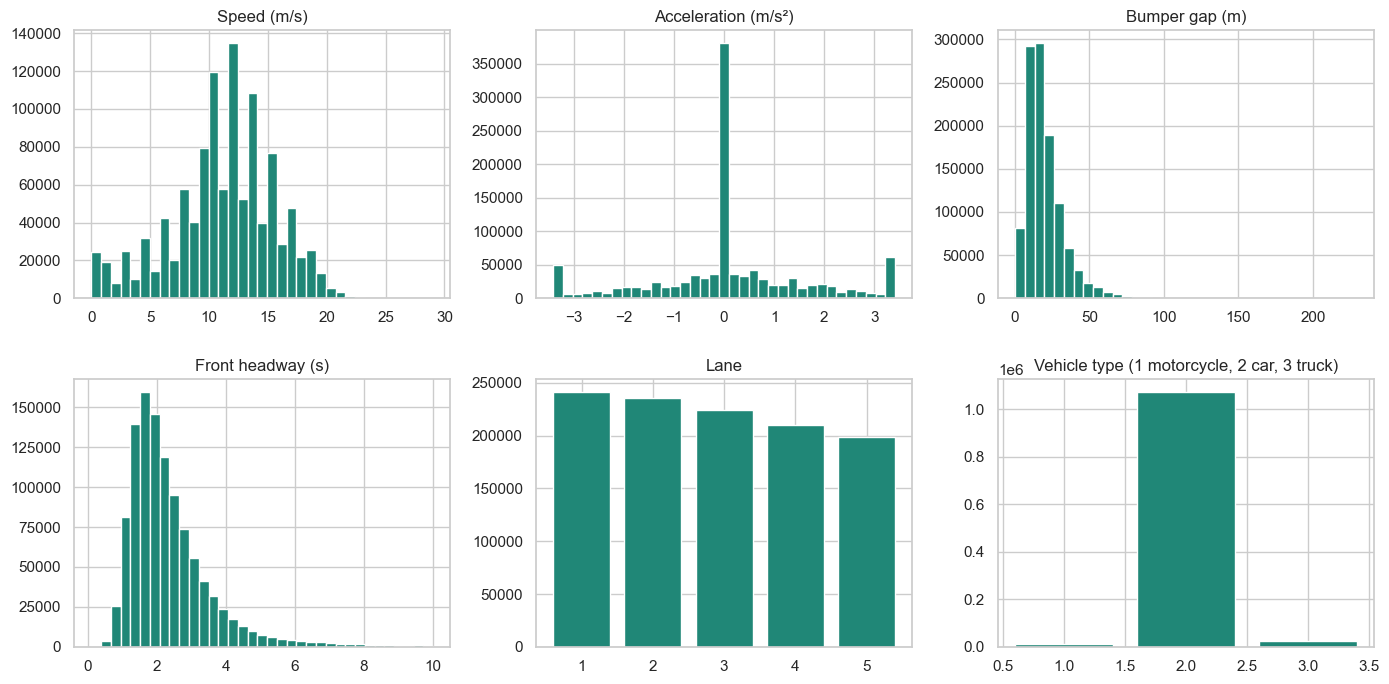

In [5]:
fig,axes=plt.subplots(2,3,figsize=(14,7))
for ax,c,title in zip(axes.flat,['v_vel','v_acc','gap','headway','lane_id','v_class'],['Speed (m/s)','Acceleration (m/s²)','Bumper gap (m)','Front headway (s)','Lane','Vehicle type (1 motorcycle, 2 car, 3 truck)']):
    values=pairs[c].replace([np.inf,-np.inf],np.nan).dropna()
    if c=='headway': values=values[values<10]
    if c in ['lane_id','v_class']:
        counts=values.value_counts().sort_index(); ax.bar(counts.index,counts.values,color='#208777')
    else: ax.hist(values,bins=35,color='#208777')
    ax.set_title(title)
plt.tight_layout(); plt.show()

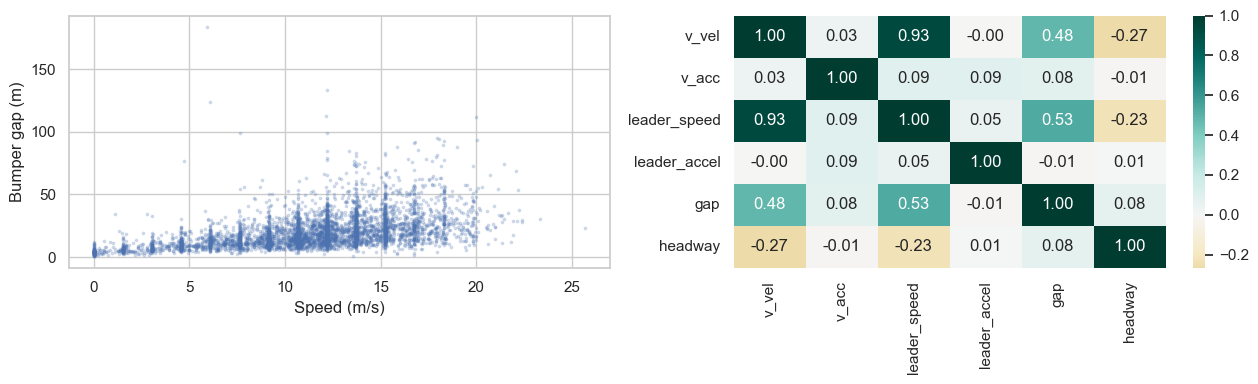

In [6]:
sample=pairs.sample(min(5000,len(pairs)),random_state=42)
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].scatter(sample.v_vel,sample.gap,s=3,alpha=.2); axes[0].set(xlabel='Speed (m/s)',ylabel='Bumper gap (m)')
sns.heatmap(sample[['v_vel','v_acc','leader_speed','leader_accel','gap','headway']].corr(),annot=True,fmt='.2f',ax=axes[1],cmap='BrBG',center=0)
plt.tight_layout(); plt.show()

## 3. Future target
Require all 20 subsequent 100 ms observations with the same valid leader/lane. Label 1 if any future front-spacing/follower-speed <1.5 s. Missing frames, stopped followers (<0.5 m/s), changed leader/lane and truncated windows are ineligible.

1.5 s is an experimental surrogate, not a universal boundary. Context-dependent headway thresholds and the distinction from TTC: https://doi.org/10.1016/S0001-4575(02)00022-2 . Inspect threshold sensitivity below.

In [7]:
pairs=pairs.sort_values(['vehicle_id','global_time']).reset_index(drop=True)
group=pairs.groupby('vehicle_id',sort=False)
future_headways=[]
valid=pairs.v_vel.ge(.5)&np.isfinite(pairs.headway)
for step in range(1,21):
    future=group[['global_time','preceding','lane_id','headway','v_vel']].shift(-step)
    valid &= future.global_time.eq(pairs.global_time+step*100)&future.preceding.eq(pairs.preceding)&future.lane_id.eq(pairs.lane_id)&future.v_vel.ge(.5)&np.isfinite(future.headway)
    future_headways.append(future.headway)
future_min=pd.concat(future_headways,axis=1).min(axis=1)
pairs['target']=(future_min<1.5).astype(int)
pairs['future_min']=future_min
eligible=pairs[valid].copy()
print('Eligible:',len(eligible),'Classes:',eligible.target.value_counts().to_dict())
print('Threshold sensitivity:',{t:float((eligible.future_min<t).mean()) for t in [1,1.5,2]})
assert set(eligible.target.unique())=={0,1}

Eligible: 993381 Classes: {0: 725125, 1: 268256}
Threshold sensitivity: {1: 0.04558975861225451, 1.5: 0.27004341737963583, 2: 0.5416521958845599}


## 4. Current features and isolated splits
Use current follower/leader speed and acceleration, front spacing and leader length. Omit redundant derived features for QDA covariance stability. No future values or lane IDs enter X.

Chronological 60/20/20 blocks. Exclude both followers and leaders whose complete trajectory crosses any boundary; add a 2 s outcome embargo. Thin to 1 Hz only after 10 Hz labeling.

In [8]:
features=['follower_speed','leader_speed','follower_accel','leader_accel','spacing_m','leader_length']
eligible=eligible.rename(columns={'v_vel':'follower_speed','v_acc':'follower_accel','space_headway':'spacing_m'})
start,end=df.global_time.min(),df.global_time.max()
cut1,cut2=start+.6*(end-start),start+.8*(end-start)
bounds=df.groupby('vehicle_id').global_time.agg(['min','max'])
parts=[]
for low,high in [(start,cut1),(cut1,cut2),(cut2,end+1)]:
    ids=bounds.index[(bounds['min']>=low)&(bounds['max']<high)]
    parts.append(eligible[eligible.vehicle_id.isin(ids)&eligible.preceding.isin(ids)&(eligible.global_time>=low)&(eligible.global_time+2000<high)&(eligible.frame_id%10==0)].copy())
train,validation,test=parts
for name,p in zip(['train','validation','test'],parts): print(name,len(p),p.target.value_counts().to_dict())
for a,b in [(train,validation),(train,test),(validation,test)]:
    assert not (set(a.vehicle_id)|set(a.preceding)) & (set(b.vehicle_id)|set(b.preceding))
X,y=train[features],train.target
assert all(p.target.nunique()==2 for p in parts)

train 53545 {0: 36876, 1: 16669}
validation 13671 {0: 9529, 1: 4142}
test 15009 {0: 12687, 1: 2322}


## 5. Comparable tuning
Same features, scaling, partitions and folds for all models. Purged expanding chronological CV inside training removes shared vehicles and includes a 2 s embargo. Scaling fits within folds. Validation F1 selects the tuned model; test stays untouched.

In [9]:
folds=[]
for fraction in [.5,.7,.85]:
    boundary=train.global_time.quantile(fraction)
    left=train[train.global_time+2000<boundary]
    right=train[(train.global_time>boundary)&(train.global_time<=boundary+.14*(cut1-start))]
    shared=(set(left.vehicle_id)|set(left.preceding)) & (set(right.vehicle_id)|set(right.preceding))
    left=left[~left.vehicle_id.isin(shared)&~left.preceding.isin(shared)]
    right=right[~right.vehicle_id.isin(shared)&~right.preceding.isin(shared)]
    if left.target.nunique()==2 and right.target.nunique()==2:
        folds.append((np.flatnonzero(train.index.isin(left.index)),np.flatnonzero(train.index.isin(right.index))))
assert len(folds)>=2
print('CV fold sizes:',[(len(a),len(b)) for a,b in folds])
def evaluate(model,part):
    pred=model.predict(part[features]); prob=model.predict_proba(part[features])[:,1]
    return dict(accuracy=accuracy_score(part.target,pred),precision=precision_score(part.target,pred,zero_division=0),recall=recall_score(part.target,pred,zero_division=0),f1=f1_score(part.target,pred,zero_division=0),roc_auc=roc_auc_score(part.target,prob),confusion_matrix=confusion_matrix(part.target,pred).tolist())
models={}; results=[]

CV fold sizes: [(23958, 5537), (34746, 5780), (42694, 5218)]


In [10]:
search=GridSearchCV(Pipeline([('scale',StandardScaler()),('model',LogisticRegression(max_iter=2000,random_state=42))]),{'model__C':[.1,1,10]},cv=folds,scoring='f1',n_jobs=1)
search.fit(X,y)
models['Logistic Regression']=search.best_estimator_
results.append(dict(name='Logistic Regression',cv_f1=search.best_score_,parameters=search.best_params_,training=evaluate(search.best_estimator_,train),validation=evaluate(search.best_estimator_,validation)))
print(results[-1])

{'name': 'Logistic Regression', 'cv_f1': np.float64(0.904728155860671), 'parameters': {'model__C': 0.1}, 'training': {'accuracy': 0.9477262115977215, 'precision': 0.9201502483945232, 'recall': 0.9111524386585877, 'f1': 0.9156292388847024, 'roc_auc': 0.9876773898253659, 'confusion_matrix': [[35558, 1318], [1481, 15188]]}, 'validation': {'accuracy': 0.9487967229902714, 'precision': 0.9278965688712083, 'recall': 0.9010140028971512, 'f1': 0.9142577168054875, 'roc_auc': 0.9877148002141826, 'confusion_matrix': [[9239, 290], [410, 3732]]}}


In [11]:
search=GridSearchCV(Pipeline([('scale',StandardScaler()),('model',LinearDiscriminantAnalysis(solver='lsqr'))]),{'model__shrinkage':[None,'auto',.1]},cv=folds,scoring='f1',n_jobs=1)
search.fit(X,y)
models['LDA']=search.best_estimator_
results.append(dict(name='LDA',cv_f1=search.best_score_,parameters=search.best_params_,training=evaluate(search.best_estimator_,train),validation=evaluate(search.best_estimator_,validation)))
print(results[-1])

{'name': 'LDA', 'cv_f1': np.float64(0.7680541495031915), 'parameters': {'model__shrinkage': None}, 'training': {'accuracy': 0.8799327668316369, 'precision': 0.8641018347319016, 'recall': 0.7289579458875758, 'f1': 0.7907975659757248, 'roc_auc': 0.9531383121820154, 'confusion_matrix': [[34965, 1911], [4518, 12151]]}, 'validation': {'accuracy': 0.8864750201155731, 'precision': 0.9126832377310389, 'recall': 0.6914534041525833, 'f1': 0.7868131868131868, 'roc_auc': 0.9595587365291518, 'confusion_matrix': [[9255, 274], [1278, 2864]]}}


In [12]:
search=GridSearchCV(Pipeline([('scale',StandardScaler()),('model',QuadraticDiscriminantAnalysis())]),{'model__reg_param':[.01,.1,.5]},cv=folds,scoring='f1',n_jobs=1)
search.fit(X,y)
models['QDA']=search.best_estimator_
results.append(dict(name='QDA',cv_f1=search.best_score_,parameters=search.best_params_,training=evaluate(search.best_estimator_,train),validation=evaluate(search.best_estimator_,validation)))
print(results[-1])

{'name': 'QDA', 'cv_f1': np.float64(0.7670298315914699), 'parameters': {'model__reg_param': 0.01}, 'training': {'accuracy': 0.8999719861798487, 'precision': 0.7852927825692237, 'recall': 0.9340692303077569, 'f1': 0.853244191144235, 'roc_auc': 0.9714047103044363, 'confusion_matrix': [[32619, 4257], [1099, 15570]]}, 'validation': {'accuracy': 0.9022748884500037, 'precision': 0.7809371245494594, 'recall': 0.9415741187831965, 'f1': 0.8537653239929948, 'roc_auc': 0.9722494178866626, 'confusion_matrix': [[8435, 1094], [242, 3900]]}}


,model,cv_f1,train_f1,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.904728,0.915629,0.948797,0.927897,0.901014,0.914258,0.987715
1,LDA,0.768054,0.790798,0.886475,0.912683,0.691453,0.786813,0.959559
2,QDA,0.767030,0.853244,0.902275,0.780937,0.941574,0.853765,0.972249


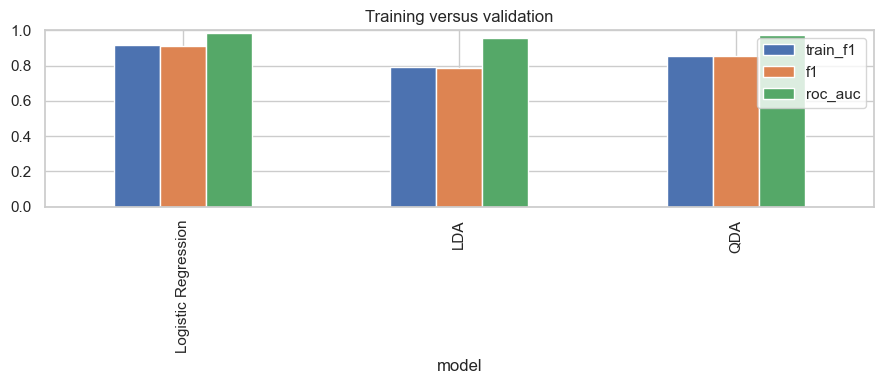

Large gaps suggest overfitting or temporal shift; close scores do not prove generalization.


In [13]:
comparison=pd.DataFrame([dict(model=r['name'],cv_f1=r['cv_f1'],train_f1=r['training']['f1'],**{k:v for k,v in r['validation'].items() if k!='confusion_matrix'}) for r in results])
display(comparison)
comparison.set_index('model')[['train_f1','f1','roc_auc']].plot.bar(ylim=(0,1),figsize=(9,4)); plt.title('Training versus validation'); plt.tight_layout(); plt.show()
print('Large gaps suggest overfitting or temporal shift; close scores do not prove generalization.')

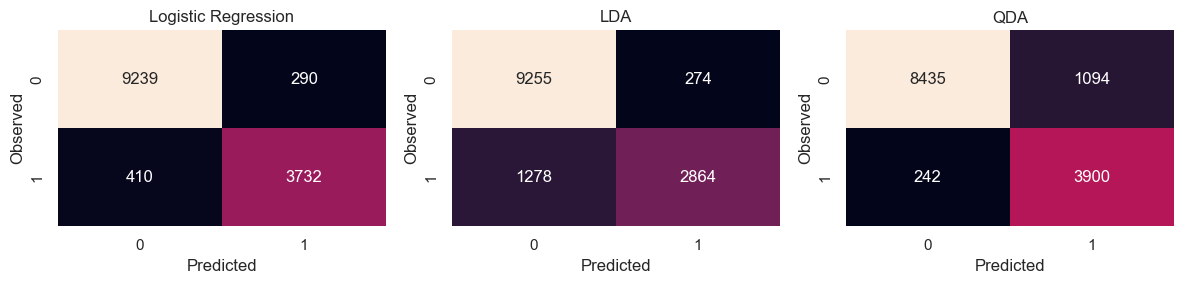

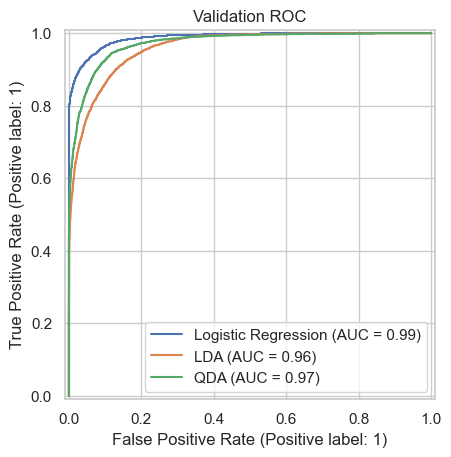

In [14]:
fig,axes=plt.subplots(1,3,figsize=(12,3))
for ax,r in zip(axes,results):
    sns.heatmap(r['validation']['confusion_matrix'],annot=True,fmt='d',cbar=False,ax=ax); ax.set(title=r['name'],xlabel='Predicted',ylabel='Observed')
plt.tight_layout(); plt.show()
for name,model in models.items(): RocCurveDisplay.from_estimator(model,validation[features],validation.target,ax=plt.gca(),name=name)
plt.title('Validation ROC'); plt.show()

## 6. Select then test once
Select validation F1, ROC-AUC breaks ties. Keep the training-fitted pipeline without refitting on validation, so the exported model equals the tested model. These uncalibrated probabilities do not establish generalization to other roads or arbitrary simulated behavior.

In [15]:
winner=max(results,key=lambda r:(r['validation']['f1'],r['validation']['roc_auc']))
selected=models[winner['name']]
test_metrics=evaluate(selected,test)
print('Selected:',winner['name']); print('Untouched test:',test_metrics)
baseline=(test.spacing_m/test.follower_speed<1.5).astype(int)
print('Current-headway persistence baseline F1:',f1_score(test.target,baseline))

Selected: Logistic Regression
Untouched test: {'accuracy': 0.961289892731028, 'precision': 0.9020785219399539, 'recall': 0.8410852713178295, 'f1': 0.8705148205928237, 'roc_auc': 0.9815324502547828, 'confusion_matrix': [[12475, 212], [369, 1953]]}
Current-headway persistence baseline F1: 0.8275517843773397


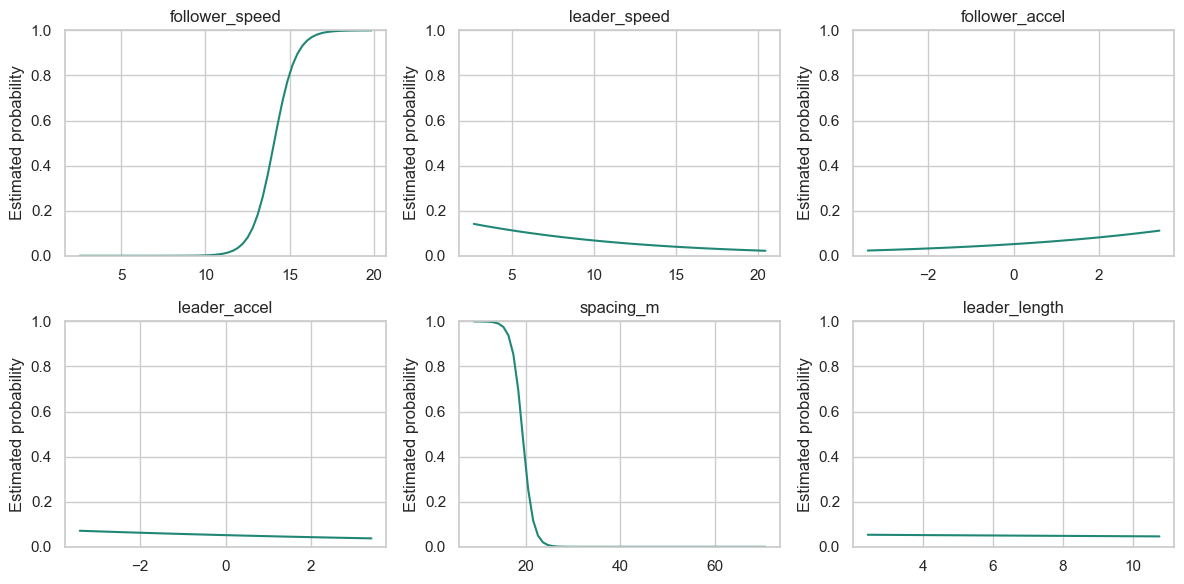

Response curves are not causal; correlated inputs can make combinations atypical.


In [16]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,feature in zip(axes.flat,features):
    grid=pd.DataFrame([X.median()]*60)
    grid[feature]=np.linspace(X[feature].quantile(.01),X[feature].quantile(.99),60)
    ax.plot(grid[feature],selected.predict_proba(grid)[:,1],color='#208777'); ax.set(title=feature,ylabel='Estimated probability',ylim=(0,1))
plt.tight_layout(); plt.show()
print('Response curves are not causal; correlated inputs can make combinations atypical.')

## 7. Export
Export fitted preprocessing/model, schema, units, ranges and real EDA/metrics. Reject runtime inputs outside training support. Same-lane predictions do not apply to lane-change collision risk.

In [17]:
info=dict(name=winner['name'],version='nearmiss-1',features=features,units=dict(follower_speed='m/s',leader_speed='m/s',follower_accel='m/s²',leader_accel='m/s²',spacing_m='m front-to-front',leader_length='m'),ranges={c:[float(X[c].min()),float(X[c].max())] for c in features},horizon_seconds=2,headway_threshold_seconds=1.5,target='Any front-to-front headway below 1.5 s in next 20 complete 100 ms observations; same leader and lane',probability_note='Uncalibrated close-following score; not collision probability')
metrics=dict(selected_model=winner['name'],comparison=results,test=test_metrics,persistence_baseline_f1=float(f1_score(test.target,baseline)),split_sizes={n:len(p) for n,p in zip(['train','validation','test'],parts)},protocol='Chronological 60/20/20; disjoint followers/leaders; 2 s embargo; purged training CV; validation F1 selection')
def histogram(values,bins=20):
    if values.name in ['lane_id','v_class']:
        return [dict(value=int(v),count=int(n)) for v,n in values.value_counts().sort_index().items()]
    counts,edges=np.histogram(values,bins=bins)
    return [dict(value=float((a+b)/2),count=int(n)) for a,b,n in zip(edges[:-1],edges[1:],counts)]
analytics=dict(rows=len(raw),vehicles=int(raw.vehicle_id.nunique()),recording_count=1,source_recording_count=3,duration_seconds=float((end-start)/1000),eligible_rows=len(eligible),positive_rate=float(eligible.target.mean()),missing_values=raw.isna().sum().to_dict(),source=SOURCE,sha256=hashlib.sha256(path.read_bytes()).hexdigest(),class_sha256=hashlib.sha256(class_path.read_bytes()).hexdigest(),vehicle_types=raw.drop_duplicates('vehicle_id').v_class.value_counts().to_dict(),threshold_sensitivity={str(t):float((eligible.future_min<t).mean()) for t in [1,1.5,2]},histograms={c:histogram(pairs[c].dropna().clip(upper=10) if c=='headway' else pairs[c].dropna()) for c in ['v_vel','v_acc','gap','headway','lane_id','v_class']},correlation=sample[['v_vel','v_acc','leader_speed','leader_accel','gap','headway']].corr().round(3).to_dict(),speed_gap=sample[['v_vel','gap']].head(500).rename(columns={'v_vel':'speed'}).to_dict('records'),statistics=df[['v_vel','v_acc','space_headway','v_length']].describe().to_dict())
joblib.dump(selected,OUT/'nearmiss.joblib')
for name,value in [('info',info),('metrics',metrics),('analytics',analytics)]:
    for folder in [OUT,PUBLIC]: (folder/f'{name}.json').write_text(json.dumps(value,indent=2,allow_nan=False),encoding='utf-8')
(OUT/'example.json').write_text(json.dumps(test[features].iloc[0].to_dict(),indent=2))
print('Exported:',OUT)

Exported: C:\Users\USER\predictive-analytics\backend\artifacts


## 8. Can this dataset support lane-change decisions?
Yes, for observed maneuvers and clearly defined conflict proxies. DOT records positions every 0.1 s, with lane IDs and surrounding traffic. The full release spans three recording periods; this notebook uses one complete period. It contains **no verified accident labels**. A simulated accident/blocked six-lane road is an illustrative scenario, not a replayed NGSIM accident.

We now extract actual adjacent mainline lane transitions. Assess each maneuver one second before its lane-ID crossing, using only then-current target-lane front/rear bumper gaps and three speeds. The driver may already be moving laterally at this point: this is a pre-crossing assessment, not proof of a decision made before maneuver initiation. Predict whether front or rear front-to-front headway falls below 1.5 s, or either bumper gap below 2 m, during the first second after crossing. This is an observed **close-conflict proxy**, not crash probability or a causal guarantee about an unattempted maneuver. Empty target lanes are handled by explicit simulation geometry rather than invented ML inputs.

In [18]:
# Actual lane transitions, not random labels or generated crashes.
tracks=df.sort_values(['vehicle_id','global_time']).copy()
previous=tracks.groupby('vehicle_id')[['lane_id','global_time']].shift()
transitions=tracks[(tracks.lane_id-previous.lane_id).abs().eq(1)&tracks.global_time.sub(previous.global_time).eq(100)].copy()
transitions['from_lane']=previous.lane_id.loc[transitions.index]
lookup=tracks.set_index(['vehicle_id','global_time'])
frames={int(t):f for t,f in tracks.groupby('global_time')}
lane_rows=[]; lane_examples=[]
for move in transitions.itertuples():
    crossing=int(move.global_time); decision=crossing-1000; target_lane=int(move.lane_id)
    times=np.arange(decision,crossing+1001,100)
    ego=lookup.reindex(pd.MultiIndex.from_product([[move.vehicle_id],times],names=lookup.index.names))
    if ego.local_y.isna().any() or not ego.lane_id.iloc[:10].eq(move.from_lane).all() or not ego.lane_id.iloc[10:].eq(target_lane).all(): continue
    current=ego.iloc[0]
    nearby=frames[decision]
    nearby=nearby[(nearby.lane_id==target_lane)&(nearby.vehicle_id!=move.vehicle_id)]
    front=nearby[nearby.local_y>current.local_y].sort_values('local_y').head(1)
    rear=nearby[nearby.local_y<=current.local_y].sort_values('local_y',ascending=False).head(1)
    if front.empty or rear.empty: continue
    front=front.iloc[0]; rear=rear.iloc[0]
    fg=front.local_y-front.v_length-current.local_y
    rg=current.local_y-current.v_length-rear.local_y
    if min(fg,rg)<=0: continue
    after_times=times[10:]
    f=lookup.reindex(pd.MultiIndex.from_product([[int(front.vehicle_id)],after_times],names=lookup.index.names))
    r=lookup.reindex(pd.MultiIndex.from_product([[int(rear.vehicle_id)],after_times],names=lookup.index.names))
    if f.local_y.isna().any() or r.local_y.isna().any() or not f.lane_id.eq(target_lane).all() or not r.lane_id.eq(target_lane).all(): continue
    e=ego.iloc[10:]
    front_spacing=f.local_y.to_numpy()-e.local_y.to_numpy()
    rear_spacing=e.local_y.to_numpy()-r.local_y.to_numpy()
    front_headway=np.divide(front_spacing,e.v_vel.to_numpy(),out=np.full(len(e),np.inf),where=e.v_vel.to_numpy()>=.5)
    rear_headway=np.divide(rear_spacing,r.v_vel.to_numpy(),out=np.full(len(e),np.inf),where=r.v_vel.to_numpy()>=.5)
    conflict=int(((front_headway<1.5)|(rear_headway<1.5)|(front_spacing-f.v_length.to_numpy()<2)|(rear_spacing-e.v_length.to_numpy()<2)).any())
    lane_rows.append(dict(vehicle_id=int(move.vehicle_id),front_id=int(front.vehicle_id),rear_id=int(rear.vehicle_id),decision_time=decision,outcome_end=crossing+1000,from_lane=int(move.from_lane),target_lane=target_lane,ego_speed=float(current.v_vel),front_speed=float(front.v_vel),rear_speed=float(rear.v_vel),front_gap=float(fg),rear_gap=float(rg),conflict=conflict))
    if len(lane_examples)<12:
        lane_examples.append(dict(vehicle_id=int(move.vehicle_id),from_lane=int(move.from_lane),target_lane=target_lane,conflict=conflict,trace=[dict(seconds=float((t-decision)/1000),x=float(row.local_y-current.local_y),lateral=float(row.local_x),lane=int(row.lane_id)) for t,(_,row) in zip(times,ego.iterrows())]))
lane_data=pd.DataFrame(lane_rows)
print('Recorded adjacent transitions:',len(transitions),'Eligible observed maneuvers:',len(lane_data))
print('Proxy outcomes:',lane_data.conflict.value_counts().to_dict())
display(lane_data.head())
assert lane_data.conflict.nunique()==2

Recorded adjacent transitions: 812 Eligible observed maneuvers: 481
Proxy outcomes: {1: 375, 0: 106}


,vehicle_id,front_id,rear_id,decision_time,outcome_end,from_lane,target_lane,ego_speed,front_speed,rear_speed,front_gap,rear_gap,conflict
0,31,25,34,1118847013800,1118847015800,5,4,12.746736,14.511528,13.844016,4.649419,7.526731,1
1,37,32,56,1118846994000,1118846996000,3,2,13.319760,11.835384,9.512808,40.899283,8.471916,0
2,40,20,47,1118847005300,1118847007300,4,3,13.944600,15.063216,13.716000,58.606944,11.444326,1
3,42,62,63,1118847034400,1118847036400,5,4,16.898112,18.437352,19.458432,9.056218,20.192390,1
4,44,37,56,1118846999800,1118847001800,1,2,13.658088,15.221712,11.140440,24.623573,7.603236,1


### Isolated lane-change training
Keep all observations of a maneuver together. Use the same chronological block boundaries, exclude crossing trajectories for ego **and both target-lane neighbors**, and keep complete outcomes inside each partition. There is one row per observed maneuver; never randomly split consecutive traffic frames. Compare the same three syllabus models with scaling fitted only on training/CV folds. The small maneuver sample and selection by drivers limit reliability; neither a low score nor the absence of a recorded proxy event proves a maneuver is safe.

In [19]:
lane_features=['ego_speed','front_speed','rear_speed','front_gap','rear_gap']
lane_parts=[]
for low,high in [(start,cut1),(cut1,cut2),(cut2,end+1)]:
    ids=bounds.index[(bounds['min']>=low)&(bounds['max']<high)]
    lane_parts.append(lane_data[lane_data.vehicle_id.isin(ids)&lane_data.front_id.isin(ids)&lane_data.rear_id.isin(ids)&(lane_data.decision_time>=low)&(lane_data.outcome_end<high)].copy())
lt,lv,le=lane_parts
for name,p in zip(['training','validation','test'],lane_parts): print(name,len(p),p.conflict.value_counts().to_dict())
for a,b in [(lt,lv),(lt,le),(lv,le)]:
    assert not set(a[['vehicle_id','front_id','rear_id']].to_numpy().ravel()) & set(b[['vehicle_id','front_id','rear_id']].to_numpy().ravel())
assert all(p.conflict.nunique()==2 for p in lane_parts)
# Purged expanding folds inside the lane-change training partition.
lane_folds=[]
for fraction in [.5,.7,.85]:
    boundary=lt.decision_time.quantile(fraction)
    a=lt[lt.outcome_end<boundary]; b=lt[lt.decision_time>boundary]
    shared=set(a[['vehicle_id','front_id','rear_id']].to_numpy().ravel()) & set(b[['vehicle_id','front_id','rear_id']].to_numpy().ravel())
    a=a[~a[['vehicle_id','front_id','rear_id']].isin(shared).any(axis=1)]
    b=b[~b[['vehicle_id','front_id','rear_id']].isin(shared).any(axis=1)]
    if a.conflict.nunique()==2 and b.conflict.nunique()==2:
        lane_folds.append((np.flatnonzero(lt.index.isin(a.index)),np.flatnonzero(lt.index.isin(b.index))))
assert len(lane_folds)>=2
print('Purged lane-change CV:',[(len(a),len(b)) for a,b in lane_folds])
def lane_evaluate(model,part):
    pred=model.predict(part[lane_features]); prob=model.predict_proba(part[lane_features])[:,1]
    return dict(accuracy=accuracy_score(part.conflict,pred),precision=precision_score(part.conflict,pred,zero_division=0),recall=recall_score(part.conflict,pred,zero_division=0),f1=f1_score(part.conflict,pred,zero_division=0),roc_auc=roc_auc_score(part.conflict,prob),confusion_matrix=confusion_matrix(part.conflict,pred).tolist())
lane_models={}; lane_results=[]
for name,estimator,grid in [('Logistic Regression',LogisticRegression(max_iter=2000,random_state=42),{'model__C':[.1,1,10]}),('LDA',LinearDiscriminantAnalysis(solver='lsqr'),{'model__shrinkage':['auto',.1]}),('QDA',QuadraticDiscriminantAnalysis(),{'model__reg_param':[.1,.5]})]:
    search=GridSearchCV(Pipeline([('scale',StandardScaler()),('model',estimator)]),grid,cv=lane_folds,scoring='f1',n_jobs=1,error_score='raise')
    search.fit(lt[lane_features],lt.conflict)
    lane_models[name]=search.best_estimator_
    lane_results.append(dict(name=name,cv_f1=search.best_score_,parameters=search.best_params_,training=lane_evaluate(search.best_estimator_,lt),validation=lane_evaluate(search.best_estimator_,lv)))
display(pd.DataFrame([dict(model=r['name'],cv_f1=r['cv_f1'],**{k:v for k,v in r['validation'].items() if k!='confusion_matrix'}) for r in lane_results]))

training 296 {1: 237, 0: 59}
validation 78 {1: 60, 0: 18}
test 49 {1: 32, 0: 17}
Purged lane-change CV: [(141, 135), (202, 86), (247, 41)]


,model,cv_f1,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.898424,0.833333,0.830986,0.983333,0.900763,0.921296
1,LDA,0.881490,0.833333,0.840580,0.966667,0.899225,0.931481
2,QDA,0.872344,0.820513,0.828571,0.966667,0.892308,0.885185


Selected lane-change proxy model: Logistic Regression Untouched test: {'accuracy': 0.7551020408163265, 'precision': 0.75, 'recall': 0.9375, 'f1': 0.8333333333333334, 'roc_auc': 0.9099264705882353, 'confusion_matrix': [[7, 10], [2, 30]]}
Always-conflict test baseline F1: 0.7901234567901234


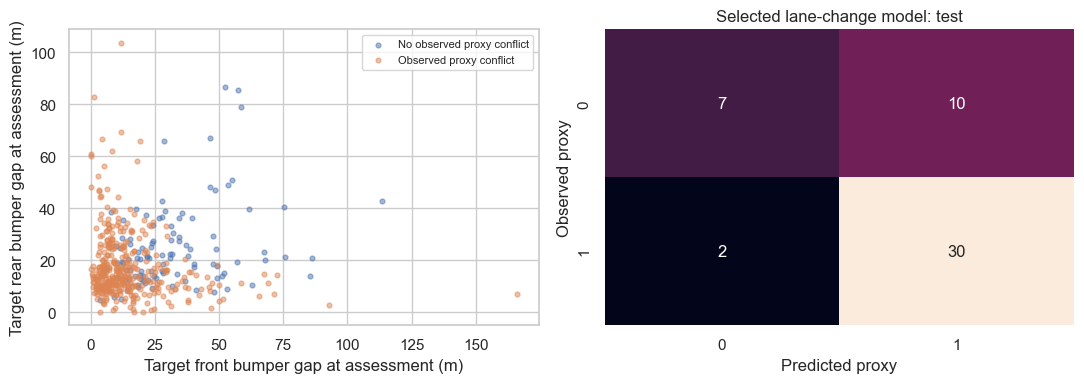

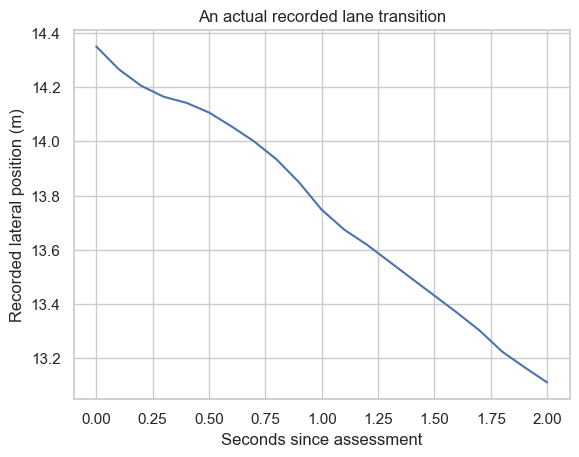

In [20]:
lane_winner=max(lane_results,key=lambda r:(r['validation']['f1'],r['validation']['roc_auc']))
lane_model=lane_models[lane_winner['name']]
lane_test=lane_evaluate(lane_model,le)
print('Selected lane-change proxy model:',lane_winner['name'],'Untouched test:',lane_test)
print('Always-conflict test baseline F1:',f1_score(le.conflict,np.ones(len(le),dtype=int)))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for label,p in [('No observed proxy conflict',lane_data[lane_data.conflict==0]),('Observed proxy conflict',lane_data[lane_data.conflict==1])]:
    axes[0].scatter(p.front_gap,p.rear_gap,s=12,alpha=.5,label=label)
axes[0].set(xlabel='Target front bumper gap at assessment (m)',ylabel='Target rear bumper gap at assessment (m)'); axes[0].legend(fontsize=8)
sns.heatmap(lane_test['confusion_matrix'],annot=True,fmt='d',cbar=False,ax=axes[1]); axes[1].set(title='Selected lane-change model: test',xlabel='Predicted proxy',ylabel='Observed proxy')
plt.tight_layout(); plt.show()
# A real trajectory crosses between lanes: no synthetic crash animation is used here.
trace=lane_examples[0]['trace']; plt.plot([p['seconds'] for p in trace],[p['lateral'] for p in trace]); plt.xlabel('Seconds since assessment'); plt.ylabel('Recorded lateral position (m)'); plt.title('An actual recorded lane transition'); plt.show()

In [21]:
lane_info=dict(name=lane_winner['name'],version='nearmiss-lane-1',features=lane_features,units={k:('m/s' if 'speed' in k else 'm bumper gap') for k in lane_features},ranges={k:[float(lt[k].min()),float(lt[k].max())] for k in lane_features},target='Observed front/rear headway below 1.5 s or bumper gap below 2 m in first second after actual lane-ID crossing; assessed 1 s before crossing',decision_threshold=.5,probability_note='Uncalibrated close-conflict proxy conditional on observed lane changes; not verified crash probability')
lane_metrics=dict(selected_model=lane_winner['name'],comparison=lane_results,test=lane_test,baseline_f1=float(f1_score(le.conflict,np.ones(len(le),dtype=int))),split_sizes={name:len(p) for name,p in zip(['train','validation','test'],lane_parts)},recorded_transitions=len(transitions),eligible_maneuvers=len(lane_data),outcomes={str(k):int(v) for k,v in lane_data.conflict.value_counts().items()},protocol='Observed maneuvers only; chronological 60/20/20; disjoint ego and both neighbors; purged expanding training CV; validation F1 selection; once-only test',examples=lane_examples,limitations=['No verified accident labels','No counterfactual labels for unattempted maneuvers','Assessment is pre-crossing, not necessarily before lateral movement begins','Small single-recording sample; probabilities uncalibrated','An empty lane is handled by geometry, not invented model inputs'])
# Exact fitted linear pipeline parameters enable genuine local inference when Render is cold.
# This is the learned model, not a manually invented risk formula.
if lane_winner['name'] in ['Logistic Regression','LDA']:
    scale=lane_model.named_steps['scale']; linear=lane_model.named_steps['model']
    lane_info['browser_model']=dict(kind='scaled-logit',mean=scale.mean_.tolist(),scale=scale.scale_.tolist(),coefficients=linear.coef_[0].tolist(),intercept=float(linear.intercept_[0]))
supported_test=le[le[lane_features].ge(lt[lane_features].min()).all(axis=1)&le[lane_features].le(lt[lane_features].max()).all(axis=1)].head(8)
assert len(supported_test)>0
lane_info['checks']=[dict(inputs=row[lane_features].to_dict(),probability=float(lane_model.predict_proba(pd.DataFrame([row[lane_features]]))[0,1])) for _,row in supported_test.iterrows()]
joblib.dump(lane_model,OUT/'lane_change.joblib')
for name,value in [('lane-info',lane_info),('lane-metrics',lane_metrics)]:
    for folder in [OUT,PUBLIC]: (folder/f'{name}.json').write_text(json.dumps(value,indent=2,allow_nan=False),encoding='utf-8')
(OUT/'lane-example.json').write_text(json.dumps(supported_test[lane_features].iloc[0].to_dict(),indent=2))
print('Lane-change artifact and actual recorded examples exported.')

Lane-change artifact and actual recorded examples exported.


### How these findings enter the simulator
For an approaching uncollided car, inspect both neighboring lanes, front/rear gaps, approaching rear vehicles and the entire lateral path. Empty lanes can be accepted by explicit geometry; a trained score is shown only when its real feature requirements and training ranges are met. For supported occupied-lane candidates, the actual fitted lane-change proxy model can veto a high-conflict estimate; a low estimate still needs geometric clearance. If ML is unavailable, the UI states that fact and uses conservative documented movement rules without inventing percentages. Cars already involved in simulated contact remain stopped obstacles.

Six displayed lanes do not imply a six-lane NGSIM training recording. Lane IDs are omitted from the model; interactions are represented by speeds and front/rear gaps. This allows illustrative geometry on 1–8 lanes without inventing lane identifiers, but does not establish external validity for six-lane incident management.

## Conclusion
This project uses real NGSIM trajectories to study future close-following conditions and close-conflict proxies around observed lane changes. Logistic Regression, LDA and QDA were compared using isolated chronological partitions. Logistic Regression achieved the highest validation F1 for both tasks. The selected models obtained test F1 scores of 0.8705 for close following and 0.8333 for the lane-change proxy.

These results do not establish verified accident prediction. The following target includes persistence of an already short headway, while the lane-change study is based on a small, imbalanced sample of observed maneuvers. Baseline comparisons, uncalibrated probabilities and the absence of counterfactual outcomes limit the conclusions. Evaluation across independent recordings is needed before claiming broader generalization.

The simulator combines learned conflict estimates with explicit clearance and movement rules. Its collisions are hypothetical geometric contacts, separate from the historical prediction targets. Recorded trajectories, generated scenarios and model-estimated scores must remain clearly distinguished.